# Decision tree baseline (6 features)
Train on May + June, test on July. Labels (`is_fraud`) are from the advisors' fraud_event_ground_truth files.

Same 6 features the rest of the team is using: lead days, account age (as new_account), booking channel, SDC4 rate code, enrollment source, nights.

In [1]:
!pip install -q shap
import os, time, shap, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, confusion_matrix, precision_recall_curve
from google.colab import drive
drive.mount("/content/drive")

def find(name):
    for r, d, fs in os.walk("/content/drive/MyDrive"):
        if name in fs:
            return os.path.join(r, name)

TRAIN_PATH = find("bookings_train_may_june_labeled.parquet")
TEST_PATH = find("bookings_test_july_labeled.parquet")
print(TRAIN_PATH)
print(TEST_PATH)

Mounted at /content/drive
/content/drive/MyDrive/wyndham_combined/bookings_train_may_june_labeled.parquet
/content/drive/MyDrive/wyndham_combined/bookings_test_july_labeled.parquet


## Load
Only the columns needed for the features.

In [2]:
cols = ["data_month", "is_fraud", "booking_timestamp", "check_in_date", "check_out_date",
        "member_enrollment_date", "booking_channel", "member_enrollment_source", "rate_code"]

train = pd.read_parquet(TRAIN_PATH, columns=cols)
test = pd.read_parquet(TEST_PATH, columns=cols)
print(train.shape, test.shape)

# should be 1600 fraud per month
pd.concat([train, test]).groupby("data_month", sort=False)["is_fraud"].agg(["count", "sum"])

(6400000, 9) (3200000, 9)


,count,sum
data_month,,
may,3200000,1600
june,3200000,1600
july,3200000,1600


## Features
Account age is a yes/no (enrolled in the last year) instead of a number of days. The same fraud accounts show up every month, so they get about 30 days older each time (median 14 days in May, 45 in June, 75 in July). With raw days the tree learned a cutoff at 59 days from May + June and missed every fraud booking in July.

In [3]:
def make_features(df):
    booked = pd.to_datetime(df["booking_timestamp"]).dt.normalize()
    check_in = pd.to_datetime(df["check_in_date"])
    check_out = pd.to_datetime(df["check_out_date"])
    enrolled = pd.to_datetime(df["member_enrollment_date"])

    X = pd.DataFrame(index=df.index)
    X["lead_days"] = (check_in - booked).dt.days
    age = (booked - enrolled).dt.days
    X["new_account"] = ((age >= 0) & (age <= 365)).astype(int)   # enrolled in the last year
    X["nights"] = (check_out - check_in).dt.days
    X["is_sdc4"] = (df["rate_code"] == "SDC4").astype(int)

    dummies = pd.get_dummies(df[["booking_channel", "member_enrollment_source"]], prefix=["ch", "src"], dtype=int)
    return pd.concat([X, dummies], axis=1)

X_train_all = make_features(train)
X_test = make_features(test).reindex(columns=X_train_all.columns, fill_value=0)
y_train_all = train["is_fraud"].values
y_test = test["is_fraud"].values

FEATURES = list(X_train_all.columns)
print(len(FEATURES), "columns after one-hot:")
print(FEATURES)

16 columns after one-hot:
['lead_days', 'new_account', 'nights', 'is_sdc4', 'ch_GDS', 'ch_Mobile App', 'ch_OTA', 'ch_Property Direct', 'ch_Voice', 'ch_Website', 'src_AUTO_ENROLL', 'src_CALL_CENTER', 'src_ONLINE_APP', 'src_ONLINE_WEB', 'src_PARTNER_CARD', 'src_PROPERTY']


## Picking the depth
Fit on May, check PR-AUC on June.

In [4]:
is_may = (train["data_month"] == "may").values
X_may, y_may = X_train_all[is_may], y_train_all[is_may]
X_june, y_june = X_train_all[~is_may], y_train_all[~is_may]

scores = {}
for depth in [3, 4, 5, 6, 8]:
    t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, class_weight="balanced", random_state=42)
    t.fit(X_may, y_may)
    scores[depth] = average_precision_score(y_june, t.predict_proba(X_june)[:, 1])
    print(depth, round(scores[depth], 4))

best_depth = max(scores, key=scores.get)
print("best depth:", best_depth)

3 0.0691
4 0.0847
5 0.1089
6 0.1522
8 0.1752
best depth: 8


## Final model: train May + June, test July

In [5]:
start = time.time()
tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=50, class_weight="balanced", random_state=42)
tree.fit(X_train_all, y_train_all)
train_time = time.time() - start

proba = tree.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
results = pd.Series({
    "precision": precision_score(y_test, pred, zero_division=0),
    "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred),
    "pr_auc": average_precision_score(y_test, proba),
    "false_positive_rate": fp / (fp + tn),
    "train_sec": train_time,
})
print(results.round(4))
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["not fraud", "fraud"], columns=["pred not fraud", "pred fraud"]))

precision              0.1788
recall                 1.0000
f1                     0.3033
pr_auc                 0.1788
false_positive_rate    0.0023
train_sec              7.6041
dtype: float64
           pred not fraud  pred fraud
not fraud         3191049        7351
fraud                   0        1600


Rows per score. A tree gives every row in the same leaf the same score, so this shows how many rows land in each leaf and how many of them are fraud.

In [6]:
scores_df = pd.DataFrame({"score": proba.round(4), "is_fraud": y_test})
scores_df.groupby("score")["is_fraud"].agg(rows="count", fraud="sum").sort_index(ascending=False).head(10)

,rows,fraud
score,,
0.9976,8951,1600
0.0000,3191049,0


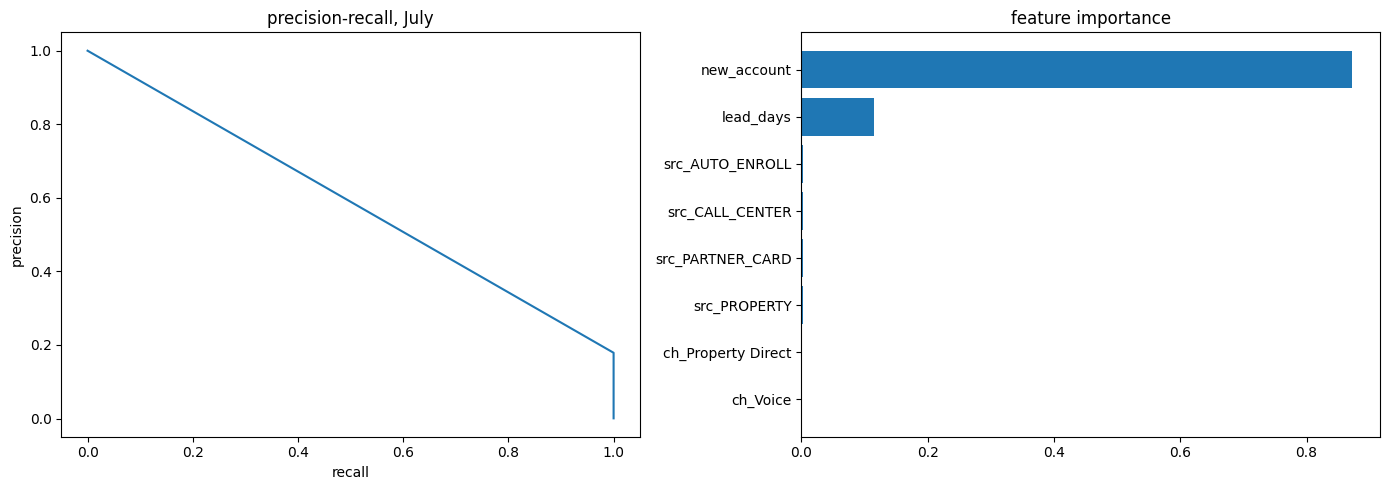

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
prec, rec, _ = precision_recall_curve(y_test, proba)
ax[0].plot(rec, prec)
ax[0].set_xlabel("recall")
ax[0].set_ylabel("precision")
ax[0].set_title("precision-recall, July")

imp = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
imp = imp[imp > 0]
ax[1].barh(imp.index, imp.values)
ax[1].set_title("feature importance")
plt.tight_layout()
plt.show()

## SHAP
All July fraud rows plus 3000 random non-fraud rows (the full test set is too big).

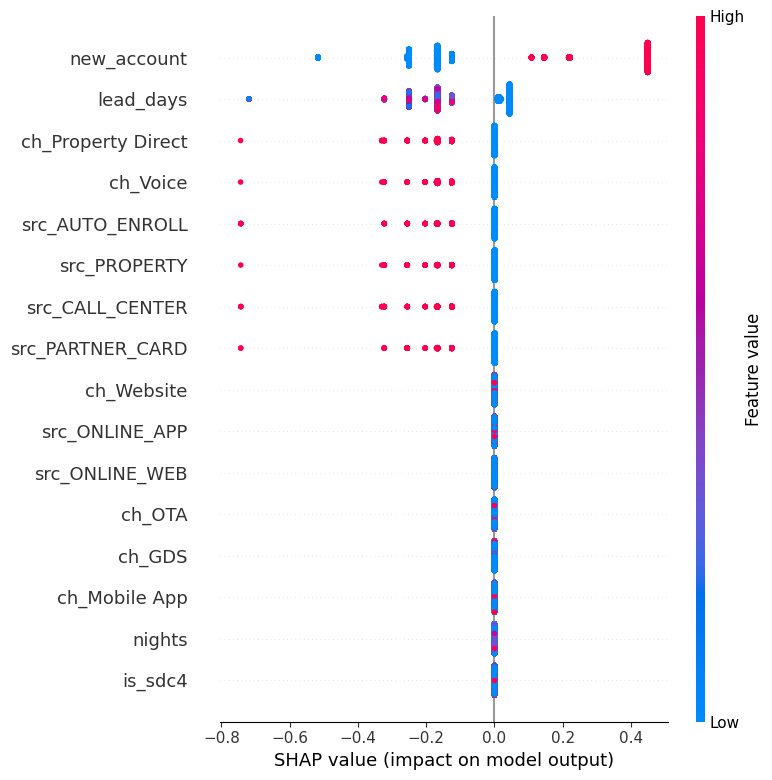

In [8]:
sample = pd.concat([X_test[y_test == 1], X_test[y_test == 0].sample(3000, random_state=42)])

explainer = shap.TreeExplainer(tree)
sv = explainer.shap_values(sample)
# older shap gives a list (one per class), newer gives one 3d array
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, sample)

## Tree rules

|--- new_account <= 0.50
|   |--- class: 0
|--- new_account >  0.50
|   |--- lead_days <= 3.50
|   |   |--- src_AUTO_ENROLL <= 0.50
|   |   |   |--- src_CALL_CENTER <= 0.50
|   |   |   |   |--- src_PARTNER_CARD <= 0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- src_PARTNER_CARD >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- src_CALL_CENTER >  0.50
|   |   |   |   |--- class: 0
|   |   |--- src_AUTO_ENROLL >  0.50
|   |   |   |--- class: 0
|   |--- lead_days >  3.50
|   |   |--- class: 0



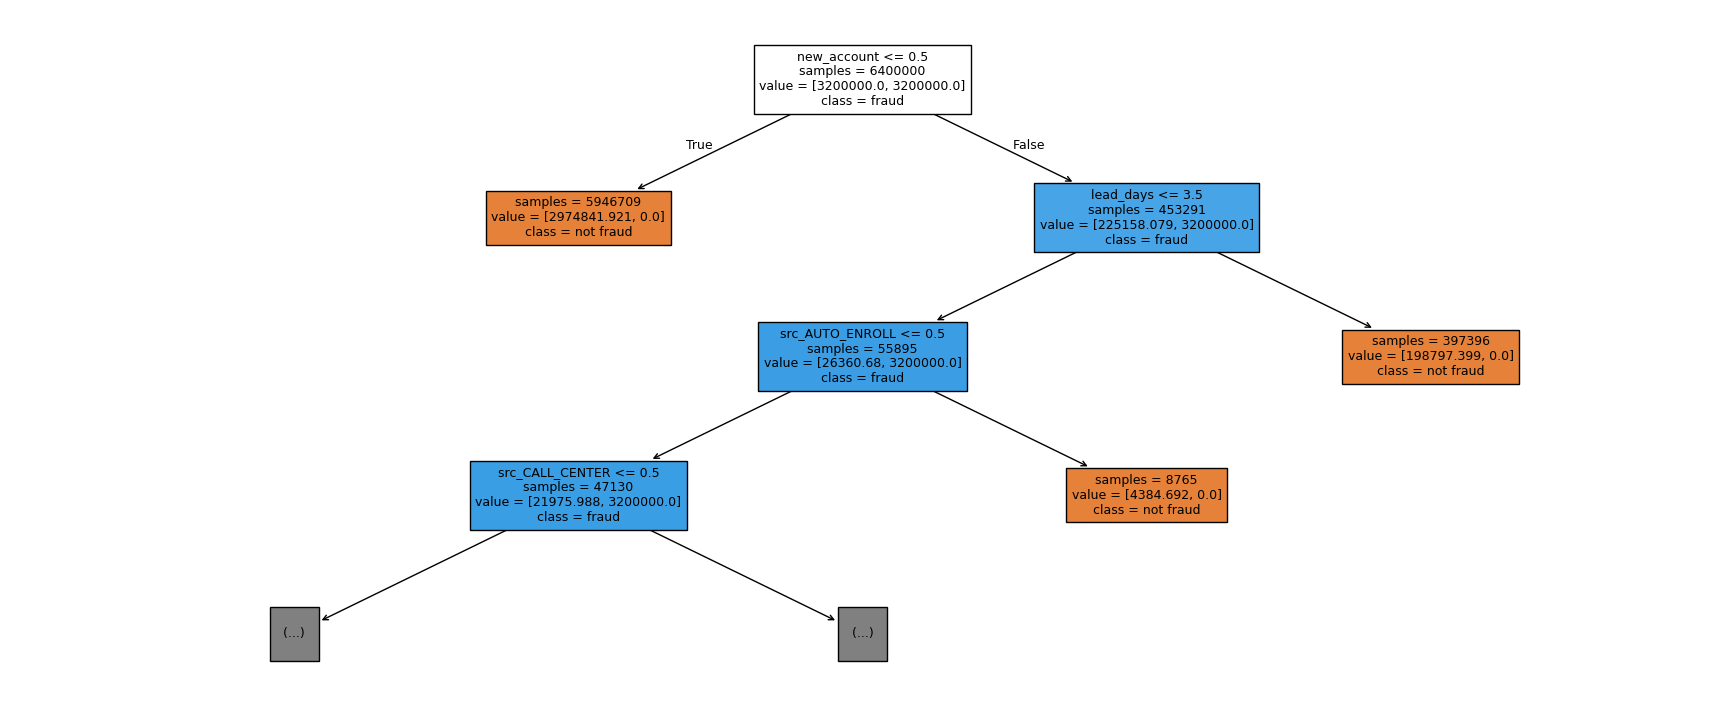

In [9]:
print(export_text(tree, feature_names=FEATURES, max_depth=4))
plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=FEATURES, class_names=["not fraud", "fraud"], max_depth=3, filled=True, impurity=False, fontsize=9)
plt.show()